# 1. Libraries

In [11]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

matplotlib.rcParams['font.family']     = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size']       = 12
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42
matplotlib.rcParams['axes.titlesize']  = 12
matplotlib.rcParams['axes.labelsize']  = 12
matplotlib.rcParams['xtick.labelsize'] = 12
matplotlib.rcParams['ytick.labelsize'] = 12

# 2. Functions

In [12]:
def filter_function_bi(t, t1, t2, rho_):
    exp1 = 4
    exp2 = 3
    rho  = 1 - rho_
    norm = np.max(np.abs(
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ))
    return (
        (t**(exp1-1))*(np.exp(-t/t1)/(t1**exp1)) -
        (t**(exp2-1))*((rho*np.exp(-t/t2))/(t2**exp2))
    ) / norm

# 3. Motion detection pathway

## 3.1 Load data

In [ ]:
path_to_data_motion = "user-path-to-motion-data"

string_motion      = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm1_OFF', 'Tm2_OFF', 'Tm4_OFF', 'Tm9_OFF']
string_plot_motion = ['L1', 'L2', 'L3', 'Mi1', 'Mi9', 'Tm3', 'Mi4', 'Tm1',     'Tm2',     'Tm4',     'Tm9'    ]
N_neurons_motion   = len(string_motion)

## 3.2 PCA

In [15]:
# Build filter matrix from fitted parameters (run Filter_notebook first to generate parameter files)
t_array  = np.arange(0.01, 5, 0.01)
F_motion = np.zeros((N_neurons_motion, t_array.size))

for i_neuron in range(N_neurons_motion):
    pars = np.loadtxt(path_to_data_motion + '/' + string_motion[i_neuron] + '_filter_parameters_polished.txt')
    F_motion[i_neuron, :] = filter_function_bi(t_array, pars[0], pars[1], pars[2])

pca_motion   = PCA(n_components=3)
X_pca_motion = pca_motion.fit_transform(F_motion)

print('Explained variance ratios:', np.round(pca_motion.explained_variance_ratio_, 3))

Explained variance ratios: [0.838 0.14  0.018]


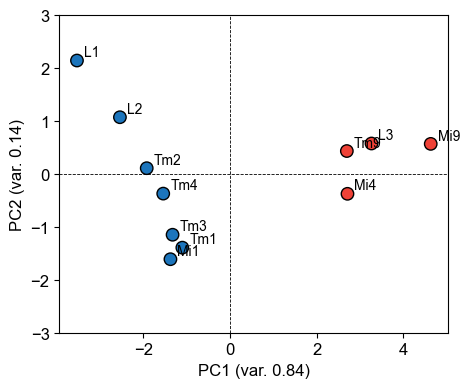

In [17]:
Fig, ax = plt.subplots(1, figsize=(5, 4))

colors_motion = ['#1c75bc' if x < 0 else '#ef4237' for x in X_pca_motion[:, 0]]

ax.scatter(X_pca_motion[:, 0], X_pca_motion[:, 1],
           c=colors_motion, s=80, edgecolor='k', zorder=3)

for i_neuron in range(N_neurons_motion):
    ax.annotate(string_plot_motion[i_neuron],
                (X_pca_motion[i_neuron, 0], X_pca_motion[i_neuron, 1]),
                fontsize=10, textcoords='offset points', xytext=(5, 3))

ax.axhline(y=0, color='k', linestyle='--', linewidth=0.6)
ax.axvline(x=0, color='k', linestyle='--', linewidth=0.6)
ax.set_xlabel('PC1 (var. ' + str(np.round(pca_motion.explained_variance_ratio_[0], 2)) + ')', fontsize=12)
ax.set_ylabel('PC2 (var. ' + str(np.round(pca_motion.explained_variance_ratio_[1], 2)) + ')', fontsize=12)
plt.tight_layout()
plt.ylim(-3, 3)
plt.savefig('PCA_motionpathway.pdf', bbox_inches='tight', dpi=300)
plt.show()